
################  TRAINING  #################

/bin/python /work/Extension_BM/baseline_train.py --N_UTs 2 --Nt 16 --cdir 'logEstTh_beamAct' 
/bin/python /work/Extension_BM/baseline_train.py --N_UTs 2 --Nt 32 --cdir 'logEstTh_beamAct'  ########## running 

/bin/python /work/Extension_BM/baseline_train.py --N_UTs 2 --Nt 16 --cdir 'logEstTh_beamAct_clutters' --if_rician True
/bin/python /work/Extension_BM/baseline_train.py --N_UTs 2 --Nt 32 --cdir 'logEstTh_beamAct_clutters' --if_rician True ########## running 


############### TEST ################
python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --N_UTs 2 --Nt 16 --eval_method genie --if_log True --cdir 'logEstTh_beamAct_clutters' --if_rician True --if_plot False

python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --N_UTs 2 --Nt 16 --eval_method estimated --if_log True --cdir 'logEstTh_beamAct_clutters' --if_rician True --if_plot False


python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --N_UTs 2 --Nt 16 --eval_method '1-TDMA' --if_log True --cdir 'logEstTh_beamAct_clutters' --if_rician True --if_plot False
python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --N_UTs 2 --Nt 16 --eval_method '7-TDMA' --if_log True --cdir 'logEstTh_beamAct_clutters' --if_rician True --if_plot False
python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --N_UTs 2 --Nt 16 --eval_method '13-TDMA' --if_log True --cdir 'logEstTh_beamAct_clutters' --if_rician True --if_plot False

python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --N_UTs 2 --Nt 16 --eval_method genie --if_log True --cdir 'logEstTh_beamAct' --if_plot False
python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --N_UTs 2 --Nt 16 --eval_method trained --if_log True --cdir 'logEstTh_beamAct' --if_plot False
python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --N_UTs 2 --Nt 16 --eval_method estimated --if_log True --cdir 'logEstTh_beamAct' --if_plot False

python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --N_UTs 2 --Nt 16 --eval_method trained --if_log True --cdir 'logEstTh_beamAct_clutters' --if_rician True --if_plot False


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
def append_csv(source_file, target_file):
    source_data = pd.read_csv(source_file, skiprows = 0)
    target_data = pd.read_csv(target_file, skiprows = 1)

    combined_data = pd.concat([source_data, target_data])
    combined_data.to_csv(target_file, index=False)

# Example usage
source_file = 'RL_mimo_ofdm/../monitor_1.csv'
target_file = 'RL_mimo_ofdm/../monitor.csv'
append_csv(source_file, target_file)



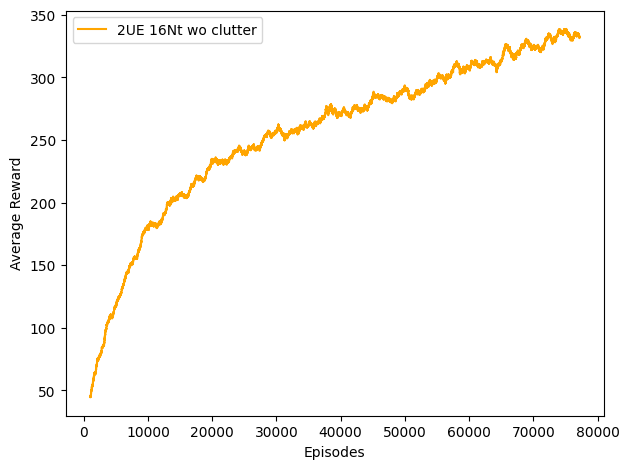

In [11]:
monitor_file = 'RL_mimo_ofdm/PPO_3ue16Nt_logEstTh_beamAct/' + "monitor.csv"

monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
fig, ax = plt.subplots()
ax.plot(moving_average,  color='orange', label='2UE 16Nt wo clutter')
ax.grid()

ax.legend()
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')
plt.tight_layout()
plt.show()

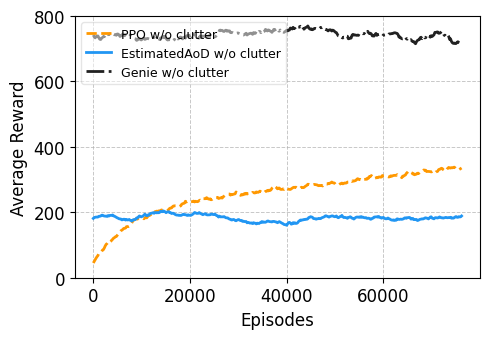

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
log_dir = 'RL_mimo_ofdm/PPO_3ue16Nt_logEstTh_beamAct/'
monitor_file = 'RL_mimo_ofdm/PPO_3ue16Nt_logEstTh_beamAct/' + "monitor.csv"

monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()

fd_trained = log_dir +'trained_09/'

fd_genie = log_dir +'genie_09/'
genie_reward = pd.read_csv(fd_genie + 'reward.csv', skiprows=0)
gr = genie_reward['Reward'].rolling(window = 100).mean()


fd_estimated = log_dir +'estimated_09/'
benchmark_reward = pd.read_csv(fd_estimated + 'reward.csv', skiprows=0)
br = benchmark_reward['Reward'].rolling(window = 100).mean()
br_length = len(br.dropna())


selected_values = moving_average[::len(moving_average)//br_length][:(br_length)]

evaluate_length = len(moving_average)

fig, ax = plt.subplots()
fig.set_size_inches(5, 3.5)

# TensorBoard style: white background, grid, thicker lines, larger font
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
colors = {
    'ppo_train': '#FF9800',      # orange
    'xie10': '#00BCD4',          # purple
    'estimated': '#2196F3',      # blue
    'genie': '#212121',          # black
    'ppo_clutter': '#4CAF50',    # green
    'estimated_clutter': '#F44336', # red
    'genie_clutter': '#795548',   # brown 
    'xie10_clutter': '#9C27B0'  # cyan
}

ax.plot(np.linspace(0, evaluate_length, br_length), selected_values.dropna(), label='PPO w/o clutter', color=colors['ppo_train'], linewidth=2, linestyle='--')
# ax.plot(np.linspace(0, evaluate_length, br_length), owr.dropna(), label='Xie[10] w/o clutter', color=colors['xie10'], linewidth=2, linestyle='-')
ax.plot(np.linspace(0, evaluate_length, br_length), br.dropna(), label='EstimatedAoD w/o clutter', color=colors['estimated'], linewidth=2, linestyle='-')
ax.plot(np.linspace(0, evaluate_length, br_length), gr.dropna(), label='Genie w/o clutter', color=colors['genie'], linewidth=2, linestyle='-.')
# ax.plot(np.linspace(0, evaluate_length, br_length), rr.dropna(), label='Random', color='red')

# Inline legend (not a standalone box)
ax.legend(
    loc='upper left',
    frameon=True,
    fontsize=9,
    fancybox=True,
    framealpha=0.5  # Set to 1.0 for opaque legend (for LaTeX EPS compatibility)
)
ax.grid(True, linestyle='--', linewidth=0.7, alpha=0.7)
ax.set_xlabel('Episodes', fontsize=12)
ax.set_ylabel('Average Reward', fontsize=12)
ax.set_ylim([0, 800])
ax.tick_params(axis='both', which='major', labelsize=12)
plt.tight_layout()


### Compare two reward function

1. $reward = \sum_{u=1}^{U} (T_u - \delta_u) + \sum_{u=1}^U \log_{1/3} \epsilon_r + \log_{1/3} \epsilon_v $ 

2. $reward = \sum_{u=1}^{U} (T_u - \delta_u) + \sum_{u=1}^U \log_{1/3} \epsilon_r + \log_{1/3} \epsilon_v + SE_u$ 

The base of logarithm, $1/3$ is chosed randomly. $\log_{1/3} \epsilon = -\frac{1}{\log 3}\log \epsilon \approx -2.5 \log\epsilon$

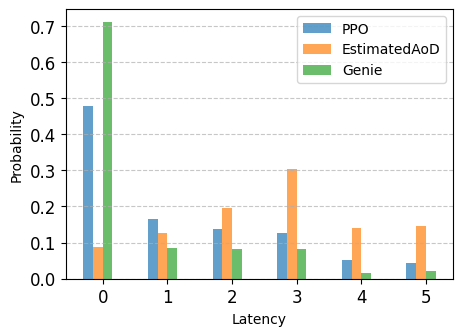

In [17]:
import matplotlib.pyplot as plt
import itertools
import pandas as pd

def load_latency(log_dir, filename):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    data1 = list(itertools.chain(*data.values))
    data2 = [x for x in data1 if x != -1]
    return data2

latency_trained = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/trained_09/', 'latency.csv')
latency_benchmark = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/estimated_09/', 'latency.csv')

latency_genie = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/genie_09/', 'latency.csv')

log_dir_clutter = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/'



#
figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO with clutter')
counts_benchmark, bins_benchmark, patches_benchmark = ax.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='EstimatedAoD with clutter')
counts_genie, bins_genie, patches_genie = ax.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie with clutter')


bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])
barwidth = 0.15
ax.cla()  # Clear the previous plot
ax.bar(bin_centers - barwidth*3/2, counts_trained, width=barwidth, align='center', alpha=0.7, label='PPO')
ax.bar(bin_centers - barwidth/2, counts_benchmark, width=barwidth, align='center', alpha=0.7, label='EstimatedAoD')
ax.bar(bin_centers + barwidth/2, counts_genie, width=barwidth, align='center', alpha=0.7, label='Genie')

# ax.bar(bin_centers - barwidth*5/2, counts_trainedwo, width=barwidth, align='center', alpha=0.7, label='PPO reward without SE')

ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend()

ax.set_xticks(bin_centers)
ax.set_xticklabels(range(6))
ax.set_xlabel('Latency')
ax.set_ylabel('Probability')
ax.tick_params(axis='both', which='major', labelsize=12)

plt.show()


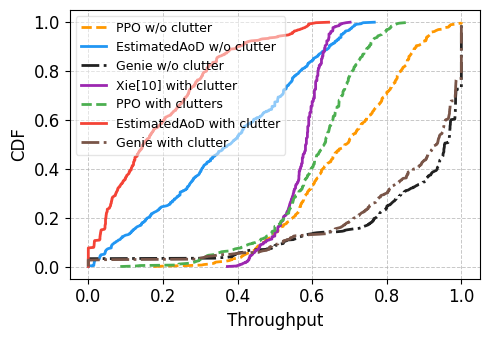

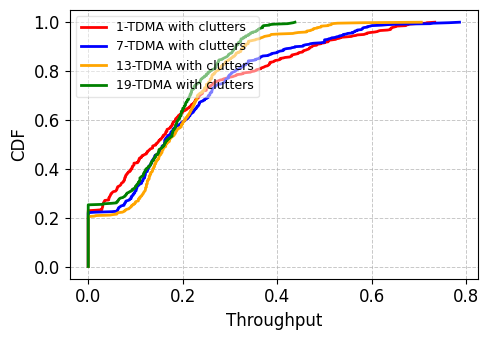

In [ ]:
def cdf_gen(log_dir, filename, item):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    cdf = np.sort(data[item])
    yvals = np.arange(len(cdf))/float(len(cdf)-1)
    return cdf, yvals

figure_handle = plt.figure()
figure_handle.set_size_inches(5,3.5)
ax = figure_handle.add_subplot()

# Use the same color and linestyle as in the averaged reward cell (colors dict)
thp_cdf, yvals = cdf_gen(fd_trained, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='--', color=colors['ppo_train'], label='PPO w/o clutter', linewidth=2)

# thp_cdf, yvals = cdf_gen(fd_otherwork, 'throughput.csv', 'Throughput')
# ax.plot(thp_cdf, yvals, linestyle='-', color=colors['xie10'], label='Xie[10] w/o clutter', linewidth=2)

thp_cdf, yvals = cdf_gen(fd_estimated, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='-', color=colors['estimated'], label='EstimatedAoD w/o clutter', linewidth=2)

thp_cdf, yvals = cdf_gen(fd_genie, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='-.', color=colors['genie'], label='Genie w/o clutter', linewidth=2)

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/other_work_09/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='-', color=colors['xie10_clutter'], label='Xie[10] with clutter', linewidth=2)

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/trained_09/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='--', color=colors['ppo_clutter'], label='PPO with clutters', linewidth=2)

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/estimated_09/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='-', color=colors['estimated_clutter'], label='EstimatedAoD with clutter', linewidth=2)

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/genie_09/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='-.', color=colors['genie_clutter'], label='Genie with clutter', linewidth=2)

ax.legend(loc='upper left', fontsize=9, frameon=True, fancybox=True, framealpha=0.5)
ax.set_xlabel('Throughput', fontsize=12)
ax.set_ylabel('CDF', fontsize=12)
ax.grid(True, linestyle='--', linewidth=0.7, alpha=0.7)
ax.tick_params(axis='both', which='major', labelsize=12)


figure_handle = plt.figure()
figure_handle.set_size_inches(5,3.5)
ax = figure_handle.add_subplot()

# TDMA curves, assign colors as you wish or keep as before
thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/1-TDMA/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='-', color='red', label='1-TDMA with clutters', linewidth=2)

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/7-TDMA/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='-', color='blue', label='7-TDMA with clutters', linewidth=2)

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/13-TDMA/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='-', color='orange', label='13-TDMA with clutters', linewidth=2)

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/19-TDMA/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, linestyle='-', color='green', label='19-TDMA with clutters', linewidth=2)

ax.legend(loc='upper left', fontsize=9, frameon=True, fancybox=True, framealpha=0.5)
ax.set_xlabel('Throughput', fontsize=12)
ax.set_ylabel('CDF', fontsize=12)
ax.grid(True, linestyle='--', linewidth=0.7, alpha=0.7)
ax.tick_params(axis='both', which='major', labelsize=12)


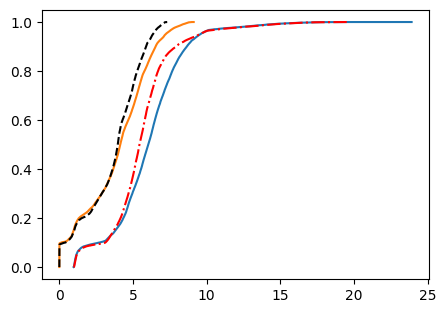

In [ ]:
# plot the CDF of SE of two users
figure_handle = plt.figure()
figure_handle.set_size_inches(5,3.5)
ax = figure_handle.add_subplot()

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/genie/', 'SE.csv', 'SE1')
ax.plot(thp_cdf, yvals, '-', label='Genie')

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/genie/', 'SE.csv', 'SE1')
ax.plot(thp_cdf, yvals, '-.', label='PPO with clutters', color = 'red')

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/genie/', 'SE.csv', 'SE2')
ax.plot(thp_cdf, yvals, '-', label='Genie')

thp_cdf, yvals = cdf_gen('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/genie/', 'SE.csv', 'SE2')
ax.plot(thp_cdf, yvals, '--', label='PPO with clutters', color = 'black')


---

### Sensing

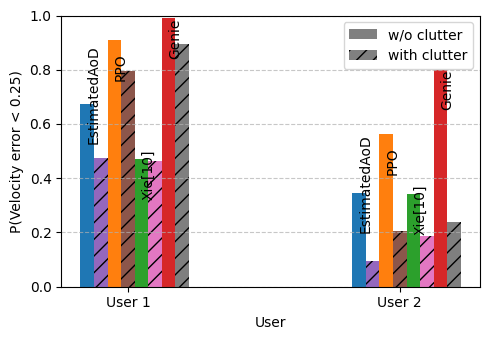

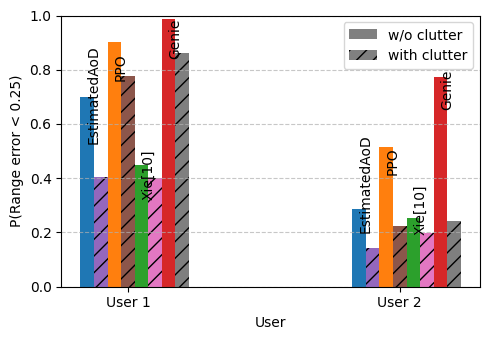

In [ ]:
from matplotlib.patches import Patch

## Range error
er_benchmark = np.array(pd.read_csv(fd_estimated + 'nmseR_allsteps.csv', skiprows=1))
er_trained = np.array(pd.read_csv(fd_trained + 'nmseR_allsteps.csv', skiprows=1))
er_genie = np.array(pd.read_csv(fd_genie + 'nmseR_allsteps.csv', skiprows=1))
er_otherwork = np.array(pd.read_csv(fd_otherwork + 'nmseR_allsteps.csv', skiprows=1))

er_benchmark_clutter = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/estimated_09/' + 'nmseR_allsteps.csv', skiprows=1))
er_trained_clutter = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/trained_09/' + 'nmseR_allsteps.csv', skiprows=1))
er_genie_clutter = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/genie_09/' + 'nmseR_allsteps.csv', skiprows=1))
er_otherwork_clutter = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/other_work_09/' + 'nmseR_allsteps.csv', skiprows=1))


## Velocity error
ev_benchmark = np.array(pd.read_csv(fd_estimated + 'nmseV_allsteps.csv', skiprows=1))
ev_trained = np.array(pd.read_csv(fd_trained + 'nmseV_allsteps.csv', skiprows=1))
ev_genie = np.array(pd.read_csv(fd_genie + 'nmseV_allsteps.csv', skiprows=1))
ev_otherwork = np.array(pd.read_csv(fd_otherwork + 'nmseV_allsteps.csv', skiprows=1))

ev_benchmark_clutter = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/estimated_09/' + 'nmseV_allsteps.csv', skiprows=1))
ev_trained_clutter = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/trained_09/' + 'nmseV_allsteps.csv', skiprows=1))
ev_genie_clutter = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/genie_09/' + 'nmseV_allsteps.csv', skiprows=1))
ev_otherwork_clutter = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/other_work_09/' + 'nmseV_allsteps.csv', skiprows=1))    

# figure_handle = plt.figure()
# ax4 = figure_handle.add_subplot()

linestyles = {'Estimated AoD': '--', 'PPO': '-', 'Genie': ':'}
labels = ['User 1', 'User 2']


def prob_error_below_threshold(data, threshold=0.2):
    return [(data[:, idx] < threshold).mean() for idx in range(data.shape[1])]


# Calculate for VELOCITY estimation error
th_prob = 0.25
prob_benchmark = prob_error_below_threshold(ev_benchmark, th_prob)
prob_trained0 = prob_error_below_threshold(ev_trained, th_prob)
prob_genie = prob_error_below_threshold(ev_genie, th_prob)
prob_otherwork = prob_error_below_threshold(ev_otherwork, th_prob)

x = np.arange(len(labels))
width = 0.1

# Replace the following with your actual computed values
prob_trained_clutter = prob_error_below_threshold(ev_trained_clutter, th_prob)
prob_benchmark_clutter = prob_error_below_threshold(ev_benchmark_clutter, th_prob)
prob_genie_clutter = prob_error_below_threshold(ev_genie_clutter, th_prob)
prob_otherwork_clutter = prob_error_below_threshold(ev_otherwork_clutter, th_prob)

half_width = width / 2

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
# Without clutters
bar1 = ax.bar(x - 3*half_width, prob_benchmark, half_width, label='EstimatedAoD w/o')
bar2 = ax.bar(x - half_width, prob_trained0, half_width,  label='PPO w/o')
bar3 = ax.bar(x + half_width, prob_otherwork, half_width,label='Xie[10] w/o')
bar4 = ax.bar(x + 3*half_width, prob_genie, half_width, label='Genie w/o')
# With clutters (bars right beside their counterparts)
bar5 = ax.bar(x - 3*half_width + half_width, prob_benchmark_clutter, half_width,  label='EstimatedAoD with clutter', hatch='//')
bar6 = ax.bar(x - half_width + half_width, prob_trained_clutter, half_width, label='PPO with clutter', hatch='//')
bar7 = ax.bar(x + half_width + half_width, prob_otherwork_clutter, half_width,  label='Xie[10] with clutter', hatch='//')
bar8 = ax.bar(x + 3*half_width + half_width, prob_genie_clutter, half_width,  label='Genie with clutter', hatch='//')

ax.set_xticks(x)
ax.set_xticklabels(labels)
# change ylabel according to th_prob
ax.set_ylabel(f'P(Velocity error < {th_prob})')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
# ax.legend(ncol=2)
# Add text labels above bars for "without clutter" bars

xpos = [x[0] - 2.5*half_width, x[0] - 0.5*half_width, x[0] + 1.5*half_width, x[0] + 3.5*half_width]
method_labels = ['EstimatedAoD', 'PPO', 'Xie[10]', 'Genie']
method_probs = [prob_benchmark, prob_trained0, prob_otherwork, prob_genie]
for i, label in enumerate(method_labels):
    ax.text(xpos[i], method_probs[i][0] - 0.15, label, ha='center', va='bottom', fontsize=10, rotation=90)
    ax.text(xpos[i]+1, method_probs[i][1] - 0.15, label, ha='center', va='bottom', fontsize=10, rotation=90)

ax.grid(axis='y', linestyle='--', alpha=0.7)

# Custom legend for "with clutter" and "without clutter"
legend_elements = [
    Patch(facecolor='gray',  label='w/o clutter', hatch=''),
    Patch(facecolor='gray',  label='with clutter', hatch='//')
]
ax.legend(handles=legend_elements, loc='upper right')

plt.show()

# Calculate for RANGE estimation error
prob_range_trained = prob_error_below_threshold(er_trained, th_prob)
prob_range_benchmark = prob_error_below_threshold(er_benchmark, th_prob)
prob_range_genie = prob_error_below_threshold(er_genie, th_prob)
prob_range_otherwork = prob_error_below_threshold(er_otherwork, th_prob)

# Example: You need to define these lists for "with clutters" results
# Replace the following with your actual computed values
prob_range_trained_clutter = prob_error_below_threshold(er_trained_clutter, th_prob)
prob_range_benchmark_clutter = prob_error_below_threshold(er_benchmark_clutter, th_prob)
prob_range_genie_clutter = prob_error_below_threshold(er_genie_clutter, th_prob)
prob_range_otherwork_clutter = prob_error_below_threshold(er_otherwork_clutter, th_prob)

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
# Without clutters
ax.bar(x - 3*half_width, prob_range_benchmark, half_width, label='Benchmark')
ax.bar(x - half_width, prob_range_trained, half_width, label='PPO reward w/o clutter')
ax.bar(x + half_width, prob_range_otherwork, half_width, label='Other work')
ax.bar(x + 3*half_width, prob_range_genie, half_width, label='Genie')
# With clutters (bars right beside their counterparts)
ax.bar(x - 3*half_width + half_width, prob_range_benchmark_clutter, half_width, label='Benchmark (clutter)', hatch='//')
ax.bar(x - half_width + half_width, prob_range_trained_clutter, half_width, label='PPO reward with clutter', hatch='//')
ax.bar(x + half_width + half_width, prob_range_otherwork_clutter, half_width, label='Other work (clutter)', hatch='//')
ax.bar(x + 3*half_width + half_width, prob_range_genie_clutter, half_width, label='Genie (clutter)', hatch='//')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel(f'P(Range error < {th_prob})')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
for i, label in enumerate(method_labels):
    ax.text(xpos[i], method_probs[i][0] - 0.15, label, ha='center', va='bottom', fontsize=10, rotation=90)
    ax.text(xpos[i]+1, method_probs[i][1] - 0.15, label, ha='center', va='bottom', fontsize=10, rotation=90)

ax.grid(axis='y', linestyle='--', alpha=0.7)

# Custom legend for "with clutter" and "without clutter"
# legend_elements = [
#     Patch(facecolor='gray',  label='w/o clutter', hatch=''),
#     Patch(facecolor='gray',  label='with clutter', hatch='//')
# ]
ax.legend(handles=legend_elements, loc='upper right')
# save the figure


#### Beam reuse

NameError: name 'count_favorU0' is not defined

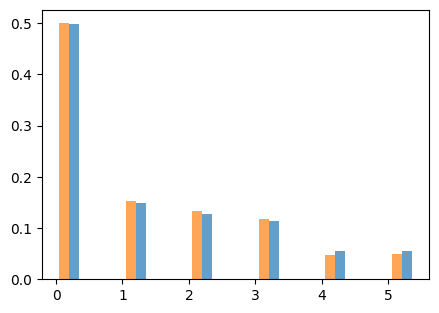

In [ ]:
figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO reward with SE')
counts_trainedwo, bins_trainedwo, pathes_trainedwo = ax.hist(latency_trained_clutter, bins=range(7), density=True, alpha=0.7, label='PPO reward w/o SE')
# count_favorU0, bins_favorU0, pathes_favorU0 = ax.hist(latency_trained_favorU0, bins=range(7), density=True, alpha=0.7, label='PPO favor U0')
# counts_favorU1, bins_favorU1, pathes_favorU1 = ax.hist(latency_traine_favorU1, bins=range(7), density=True, alpha=0.7, label='PPO favor U1')
# counts_shuffled, bins_shuffled, pathes_shuffled = ax.hist(latency_trained_shuffled, bins=range(7), density=True, alpha=0.7, label='PPO trained shuffled')

bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])
barwidth = 0.15
ax.cla()  # Clear the previous plot
ax.bar(bin_centers - barwidth*3/2, counts_trained, width=barwidth, align='center', alpha=0.7, label='PPO reward with SE')
ax.bar(bin_centers - barwidth*5/2, counts_trainedwo, width=barwidth, align='center', alpha=0.7, label='PPO reward w/o SE (shuffled)')
ax.bar(bin_centers - barwidth/2, count_favorU0, width=barwidth, align='center', alpha=0.7, label='PPO favor U0')
ax.bar(bin_centers + barwidth/2, counts_favorU1, width=barwidth, align='center', alpha=0.7, label='PPO favor U1')
# ax.bar(bin_centers + barwidth*3/2, counts_shuffled, width=barwidth, align='center', alpha=0.7, label='PPO trained shuffled')

ax.set_xticks(bin_centers)

ax.set_xticks(bin_centers)
ax.set_xticklabels(range(6))
ax.set_xlabel('Latency')
ax.set_ylabel('Probability')
ax.legend()

- PPO reward w/o SE
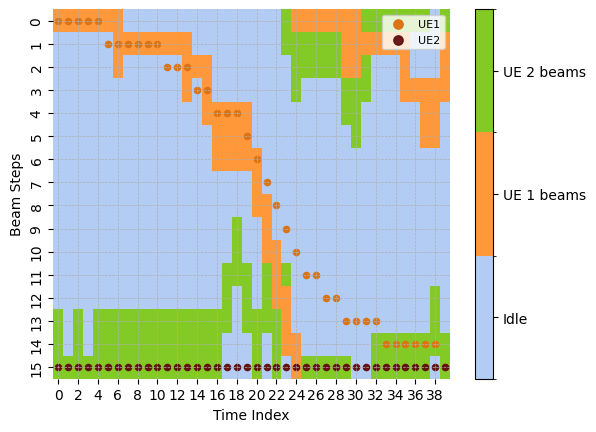
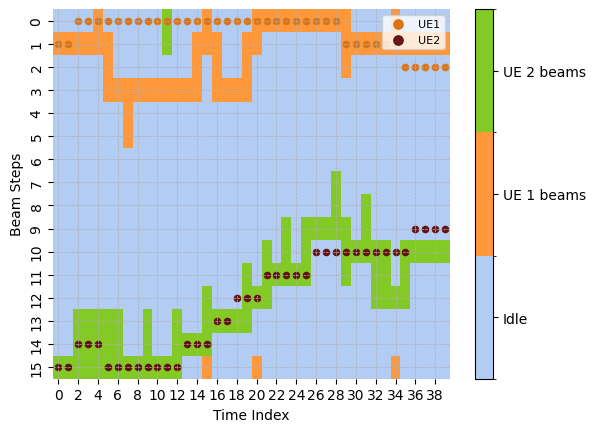

- PPO reward with SE
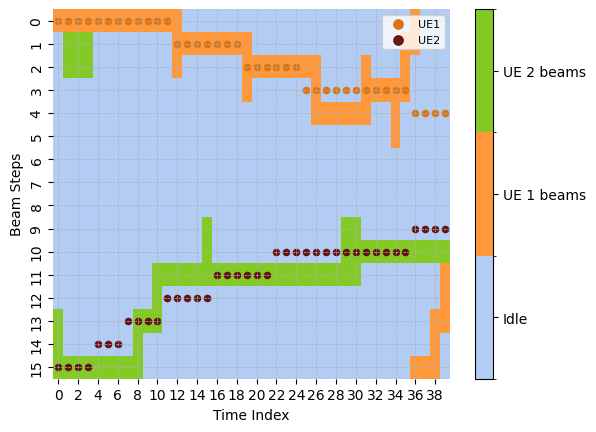
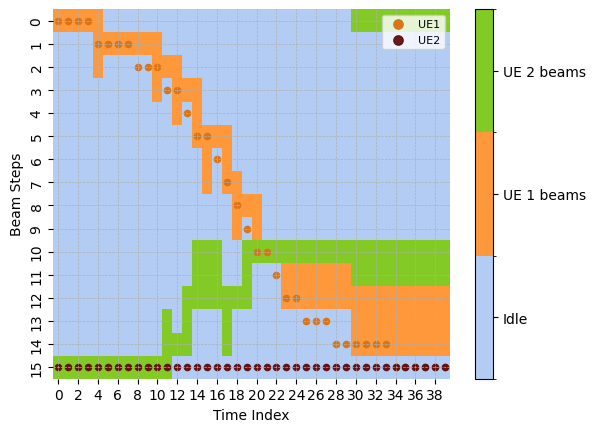

### More antennas



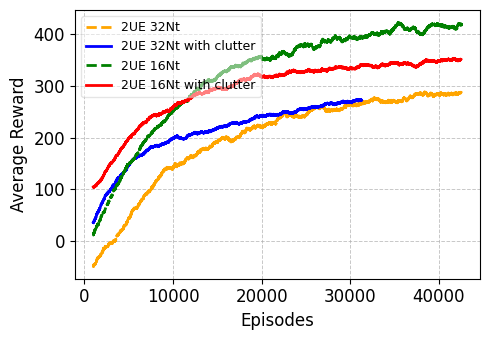

In [ ]:
# plot reward compared between 16 Nt and 32 Nt
figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()    

monitor_data = pd.read_csv('RL_mimo_ofdm/PPO_2ue32Nt_logEstTh_beamAct/monitor.csv', skiprows=0)
window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
ax.plot(moving_average, color='orange', label='2UE 32Nt', linewidth=2, linestyle='--')

monitor_data = pd.read_csv('RL_mimo_ofdm/PPO_2ue32Nt_logEstTh_beamAct_clutters/monitor.csv', skiprows=0)
window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
ax.plot(moving_average, color='blue', label='2UE 32Nt with clutter', linewidth=2)

monitor_data = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/monitor.csv', skiprows=0)
window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
ax.plot(moving_average, color='green', label='2UE 16Nt', linewidth=2, linestyle='--')
monitor_data = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/monitor.csv', skiprows=0)
window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
ax.plot(moving_average, color='red', label='2UE 16Nt with clutter', linewidth=2)

ax.legend(loc='upper left', fontsize=9, frameon=True, fancybox=True, framealpha=0.5)
ax.set_xlabel('Episodes', fontsize=12)
ax.set_ylabel('Average Reward', fontsize=12)
ax.grid(True, linestyle='--', linewidth=0.7, alpha=0.7)
ax.tick_params(axis='both', which='major', labelsize=12)
plt.tight_layout()

plt.show()

### More users


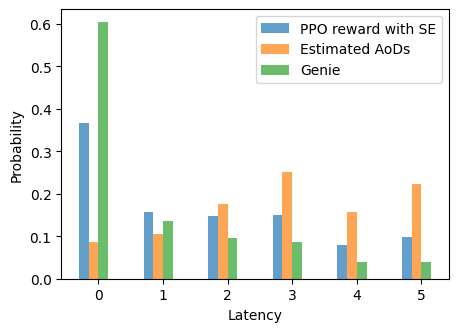

In [ ]:
log_dir = 'RL_mimo_ofdm/PPO_3ue16Nt_logEstTh_beamAct/'

fd_trained = log_dir +'trained/'

fd_genie = log_dir +'genie/'

fd_estimated = log_dir +'estimated/'

latency_trained = load_latency(fd_trained, 'latency.csv')
latency_benchmark = load_latency(fd_estimated, 'latency.csv')

latency_genie = load_latency(fd_genie , 'latency.csv')


figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO reward with SE')
counts_benchmark, bins_benchmark, patches_benchmark = ax.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie, bins_genie, patches_genie = ax.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie')



bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])
barwidth = 0.15
ax.cla()  # Clear the previous plot
ax.bar(bin_centers - barwidth*3/2, counts_trained, width=barwidth, align='center', alpha=0.7, label='PPO reward with SE')
ax.bar(bin_centers - barwidth/2, counts_benchmark, width=barwidth, align='center', alpha=0.7, label='Estimated AoDs')
ax.bar(bin_centers + barwidth/2, counts_genie, width=barwidth, align='center', alpha=0.7, label='Genie')


ax.set_xticks(bin_centers)

ax.set_xticks(bin_centers)
ax.set_xticklabels(range(6))
ax.set_xlabel('Latency')
ax.set_ylabel('Probability')
ax.legend()


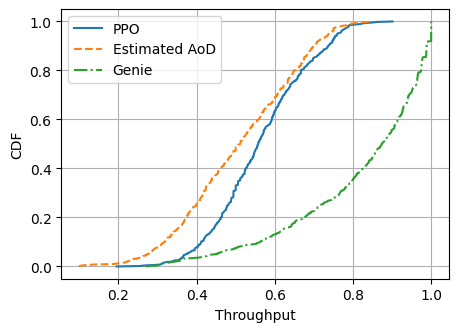

In [ ]:
figure_handle = plt.figure()
figure_handle.set_size_inches(5,3.5)
ax = figure_handle.add_subplot()

thp_cdf, yvals = cdf_gen(fd_trained, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-', label='PPO')

thp_cdf, yvals = cdf_gen(fd_estimated, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '--', label='Estimated AoD')

thp_cdf, yvals = cdf_gen(fd_genie, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-.', label='Genie')


ax.legend()
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()

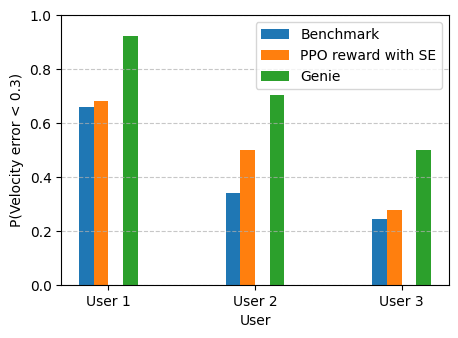

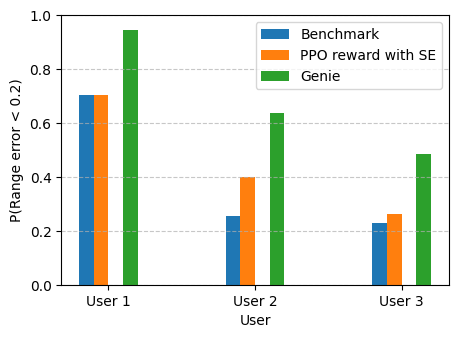

In [ ]:
er_t = pd.read_csv(fd_trained + 'nmseR_allsteps.csv', skiprows=1)
er_b = pd.read_csv(fd_estimated + 'nmseR_allsteps.csv', skiprows=1)
er_g = pd.read_csv(fd_genie + 'nmseR_allsteps.csv', skiprows=1)


er_benchmark = np.array(er_b)
er_trained = np.array(er_t)
er_genie = np.array(er_g)


ev_t = pd.read_csv(fd_trained + 'nmseV_allsteps.csv', skiprows=1)
ev_b = pd.read_csv(fd_estimated + 'nmseV_allsteps.csv', skiprows=1)
ev_g = pd.read_csv(fd_genie + 'nmseV_allsteps.csv', skiprows=1)


ev_benchmark = np.array(ev_b)
ev_trained = np.array(ev_t)
ev_genie = np.array(ev_g)

# figure_handle = plt.figure()
# ax4 = figure_handle.add_subplot()

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']
linestyles = {'Estimated AoD': '--', 'PPO': '-', 'Genie': ':'}
labels = ['User 1', 'User 2', 'User 3']


def prob_error_below_threshold(data, threshold=0.2):
    return [(data[:, idx] < threshold).mean() for idx in range(data.shape[1])]


th_prob = 0.3
prob_benchmark = prob_error_below_threshold(ev_benchmark, th_prob)
prob_trained0 = prob_error_below_threshold(ev_trained, th_prob)
prob_genie = prob_error_below_threshold(ev_genie, th_prob)
prob_trained_woSE = prob_error_below_threshold(ev_trained_woSE, th_prob)
x = np.arange(len(labels))
width = 0.1

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - 3*width/2, prob_benchmark, width, label='Benchmark')
ax.bar(x - width/2 , prob_trained0, width, label='PPO reward with SE')
# ax.bar(x + width/2, prob_trained_woSE, width, label='PPO reward w/o SE')
ax.bar(x + 3*width/2, prob_genie, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(Velocity error < 0.3)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Calculate for range estimation error
prob_range_trained = prob_error_below_threshold(er_trained, th_prob)
prob_range_benchmark = prob_error_below_threshold(er_benchmark, th_prob)
prob_range_genie = prob_error_below_threshold(er_genie, th_prob)
# prob_range_trained_woSE = prob_error_below_threshold(er_trained_woSE, th_prob)

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - 3*width/2, prob_range_benchmark, width, label='Benchmark')
ax.bar(x - width/2, prob_range_trained, width, label='PPO reward with SE')
# ax.bar(x + width/2, prob_range_trained_woSE, width, label='PPO w/o SE')
ax.bar(x + 3*width/2, prob_range_genie, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(Range error < 0.2)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Discussion: 
1. The BS does not require a specific waveform for sensing. This ISAC scheme allows sensing without sharing many resources from communication. This can be also taken as \emph{sensing for free} which is a phenomenon proposed in \cite{}. In \cite{}, \enph{sensing for free} happens only when there exist some residule time resources after the optimal scheduling is employed. In our case, sensing for free happens constantly in the time domain through taking advantages of the structure of mono-static passive radar. Nevertheless, the tradeoff between the two modules manifests as the number of beams. Multiple beams give a bigger FoV, which improves the prediction of future beams, but yield dispersion of transmitted power towards the user, degrading the communication performance. On the other hand, ????

2. User-beam association: AoD estimation methods, such as MUSIC, achieve decent performance. They nevertheless suffer from the user-beam association problem when there are multiple users. The association information is acknowledged to the BS via user feedback channel after the users obtained the optimal one from the BS sweept beams. For the trained PPO method, the agent acquires such information based on the previous allocation beams which is input as part of the state. In addition, the AoD-estimated method is expected to have degraded performance when there are clutters in the environment as the they contribute to the refelcted echoes. The BS requires further information to distinguish AoDs of users from these of clutters. On contrary, the PPO agent learns the environment implicitly via the network. For a fair comparison, we consider that the BS has the user-beam association information while adopting the benchmark: AoD-estimated method. The comparison between a clean environment and a clutter-existed environment is shown in Section \ref{}. 


3. The amount of feedback bits: 

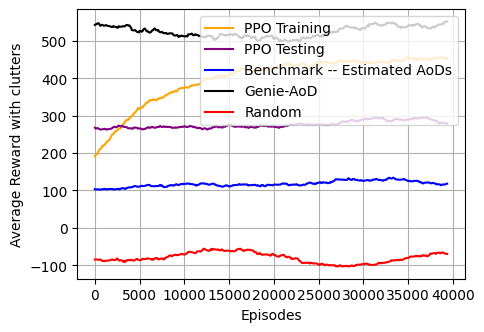

In [ ]:
log_dir = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct_clutters/'
monitor_data = pd.read_csv(log_dir + 'monitor_2.csv', skiprows=0)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
selected_values = moving_average[::len(moving_average)//br_length][:(br_length)]
ax.plot(np.linspace(0, len(selected_values), br_length), selected_values, label='PPO_training_with_clutters', color='green')

fd_trained = log_dir +'trained/'
trained_reward = pd.read_csv(fd_trained + 'reward.csv', skiprows=0)
tr = trained_reward['Reward'].rolling(window = 100).mean()

fd_genie = log_dir +'genie/'
genie_reward = pd.read_csv(fd_genie + 'reward.csv', skiprows=0)
gr = genie_reward['Reward'].rolling(window = 100).mean()


fd_estimated = log_dir +'estimated/'
benchmark_reward = pd.read_csv(fd_estimated + 'reward.csv', skiprows=0)
br = benchmark_reward['Reward'].rolling(window = 100).mean()

fig, ax = plt.subplots()
fig.set_size_inches(5, 3.5)
ax.plot(np.linspace(0, len(moving_average), br_length), selected_values.dropna(), label='PPO Training', color='orange')
ax.plot(np.linspace(0, len(moving_average), br_length), tr.dropna(), label='PPO Testing', color='purple')
ax.plot(np.linspace(0, len(moving_average), br_length), br.dropna(), label='Benchmark -- Estimated AoDs', color='blue')
ax.plot(np.linspace(0, len(moving_average), br_length), gr.dropna(), label='Genie-AoD', color='black')
ax.plot(np.linspace(0, len(moving_average), br_length), rr.dropna(), label='Random', color='red')
# ax.plot(np.linspace(0, len(moving_average), br_length), tr2.dropna(), label='PPO_128_new_statespace Test Test', color='red')

ax.legend(loc='upper right')
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward with clutters')

latency_trained = load_latency(fd_trained, 'latency.csv')
latency_benchmark = load_latency(fd_estimated, 'latency.csv')

latency_genie = load_latency(fd_genie , 'latency.csv')
latency_r = load_latency(fd_random , 'latency.csv')

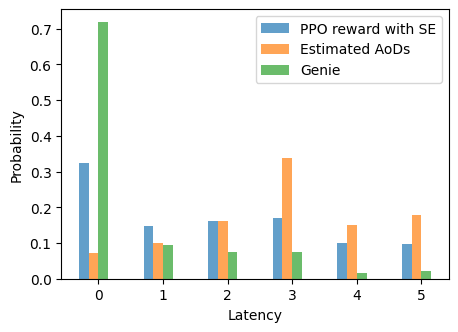

In [ ]:
figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO reward with SE')
counts_benchmark, bins_benchmark, patches_benchmark = ax.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie, bins_genie, patches_genie = ax.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie')



bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])
barwidth = 0.15
ax.cla()  # Clear the previous plot
ax.bar(bin_centers - barwidth*3/2, counts_trained, width=barwidth, align='center', alpha=0.7, label='PPO reward with SE')
ax.bar(bin_centers - barwidth/2, counts_benchmark, width=barwidth, align='center', alpha=0.7, label='Estimated AoDs')
ax.bar(bin_centers + barwidth/2, counts_genie, width=barwidth, align='center', alpha=0.7, label='Genie')


ax.set_xticks(bin_centers)

ax.set_xticks(bin_centers)
ax.set_xticklabels(range(6))
ax.set_xlabel('Latency')
ax.set_ylabel('Probability')
ax.legend()

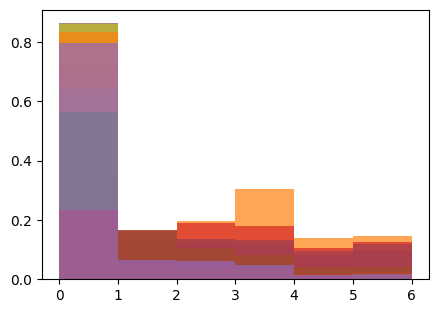

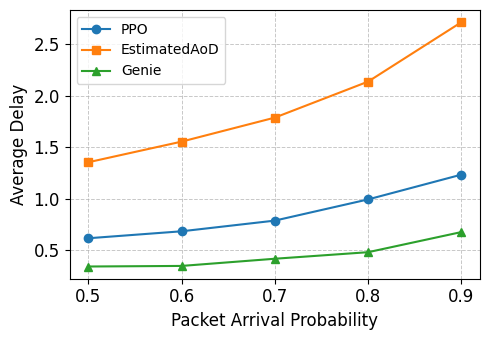

In [ ]:
fd_trained_05 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/trained_05/'
fd_estimated_05 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/estimated_05/'
fd_genie_05 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/genie_05/'

fd_trained_06 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/trained_06/'
fd_estimated_06 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/estimated_06/'
fd_genie_06 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/genie_06/'

fd_trained_07 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/trained_07/'
fd_estimated_07 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/estimated_07/'
fd_genie_07 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/genie_07/'

fd_trained_08 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/trained_08/'
fd_estimated_08 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/estimated_08/'
fd_genie_08 = 'RL_mimo_ofdm/PPO_2ue16Nt_logEstTh_beamAct/genie_08/'

latency_trained_09 = load_latency(fd_trained, 'latency.csv')
latency_benchmark_09 = load_latency(fd_estimated, 'latency.csv')
latency_genie_09 = load_latency(fd_genie, 'latency.csv')

latency_trained_08 = load_latency(fd_trained_08, 'latency.csv')
latency_benchmark_08 = load_latency(fd_estimated_08, 'latency.csv')
latency_genie_08 = load_latency(fd_genie_08, 'latency.csv')

latency_trained_05 = load_latency(fd_trained_05, 'latency.csv')
latency_benchmark_05 = load_latency(fd_estimated_05, 'latency.csv')
latency_genie_05 = load_latency(fd_genie_05, 'latency.csv')

latency_trained_06 = load_latency(fd_trained_06, 'latency.csv')
latency_benchmark_06 = load_latency(fd_estimated_06, 'latency.csv')
latency_genie_06 = load_latency(fd_genie_06, 'latency.csv')

latency_trained_07 = load_latency(fd_trained_07, 'latency.csv')
latency_benchmark_07 = load_latency(fd_estimated_07, 'latency.csv')
latency_genie_07 = load_latency(fd_genie_07, 'latency.csv')

counts_trained = np.zeros([6,5])
counts_benchmark = np.zeros([6,5])
counts_genie = np.zeros([6,5])

fig, ax2 = plt.subplots()
fig.set_size_inches(5, 3.5)

counts_trained[:,4], _, _ = ax2.hist(latency_trained_09, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,4], _, _ = ax2.hist(latency_benchmark_09, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,4], _, _ = ax2.hist(latency_genie_09, bins=range(7), density=True, alpha=0.7, label='Genie')

counts_trained[:,0], _, _ = ax2.hist(latency_trained_05, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,0], _, _ = ax2.hist(latency_benchmark_05, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,0], _, _ = ax2.hist(latency_genie_05, bins=range(7), density=True, alpha=0.7, label='Genie')

counts_trained[:,1], _, _ = ax2.hist(latency_trained_06, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,1], _, _ = ax2.hist(latency_benchmark_06, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,1], _, _ = ax2.hist(latency_genie_06, bins=range(7), density=True, alpha=0.7, label='Genie')

counts_trained[:,2], _, _ = ax2.hist(latency_trained_07, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,2], _, _ = ax2.hist(latency_benchmark_07, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,2], _, _ = ax2.hist(latency_genie_07, bins=range(7), density=True, alpha=0.7, label='Genie')    

counts_trained[:,3], _, _ = ax2.hist(latency_trained_08, bins=range(7), density=True, alpha=0.7, label='PPO')
counts_benchmark[:,3], _, _ = ax2.hist(latency_benchmark_08, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie[:,3], _, _ = ax2.hist(latency_genie_08, bins=range(7), density=True, alpha=0.7, label='Genie')

# Calculate average delays
ave_delay_trained = np.dot(range(6), counts_trained)
ave_delay_estimated = np.dot(range(6), counts_benchmark)
ave_delay_genie = np.dot(range(6), counts_genie)


fig, ax = plt.subplots()
fig.set_size_inches(5, 3.5)
arrival_prob = [0.5, 0.6, 0.7, 0.8, 0.9]

ax.plot(arrival_prob, ave_delay_trained, marker='o', label='PPO')
ax.plot(arrival_prob, ave_delay_estimated, marker='s', label='EstimatedAoD')
ax.plot(arrival_prob, ave_delay_genie, marker='^', label='Genie')
ax.set_xticks(arrival_prob)
ax.set_xticklabels(arrival_prob)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.set_xlabel('Packet Arrival Probability', fontsize=12)
ax.set_ylabel('Average Delay', fontsize=12)
ax.legend()
ax.grid(True, linestyle='--', linewidth=0.7, alpha=0.7 )
plt.tight_layout()
